<a href="https://colab.research.google.com/github/Kevan123/Applied-Operations-Research/blob/main/COMP6925_Assignment1_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COMP6925 Applied Operations Research
## Assignment 1

**Student:** Kevan Rajaram  
**Student ID:** 809001312  
**Due Date:** 3 October 2026

This notebook contains the mathematical formulations, implementations, numerical results, figures, and interpretations for all three [questions](https://drive.google.com/file/d/1TmrJewKrlSJelxrRrVk-qTAUp1ps3OuR/view?usp=drive_link).

It is designed to run from a clean Google Colab runtime using **Runtime → Run all**. All problem data are embedded; no external input files are required.


## Python libraries setup

Questions 1 and 2 use mainly NumPy, pandas, and Matplotlib.

In [ ]:
%pip -q install numpy pandas matplotlib sympy

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp

np.set_printoptions(precision=8, suppress=True)
pd.set_option("display.float_format", lambda value: f"{value:.8f}")

# Question 1 Golden Section Search



## 1(a) Convexity and uniqueness

The objective is

$$f(x)=x^4+x^2-3x+2, \qquad -2\leq x\leq2.$$

Its first two derivatives are

$$f'(x)=4x^3+2x-3,$$

$$f''(x)=12x^2+2.$$

Since $12x^2+2\geq2>0$ for every $x\in[-2,2]$, $f$ is strictly convex on the entire interval. Therefore, it has at most one minimizer.

Further, $f'(-2)=-39<0$ and $f'(2)=33>0$. By continuity, $f'$ has a zero in $[-2,2]$, and strict convexity makes this stationary point the unique global minimizer. A strictly convex function is unimodal, so golden-section search is appropriate.

*This is reinforced with the computation and diagram below.*

In [ ]:
# Define the symbolic variable and objective function
x = sp.symbols('x', real=True)

f_objective = x**4 + x**2 - 3*x + 2

# Compute first and second derivatives symbolically
f_prime = sp.diff(f_objective, x)
f_second = sp.diff(f_prime, x)

print("Objective function:")
print("f(x)   =", f_objective)

print("\nFirst derivative:")
print("f'(x)  =", f_prime)

print("\nSecond derivative:")
print("f''(x) =", f_second)

# Evaluate the second derivative over [-2, 2]

x_values = np.linspace(-2, 2, 1000)

f_second_numeric = sp.lambdify(x, f_second, "numpy")
second_derivative_values = f_second_numeric(x_values)

print(
    f"Minimum value of f''(x) on [-2, 2] = "
    f"{np.min(second_derivative_values):.6f}"
)

if np.all(second_derivative_values > 0):
    print("f''(x) > 0 throughout [-2, 2].")
    print("Therefore, f(x) is strictly convex on [-2, 2].")

Objective function:
f(x)   = x**4 + x**2 - 3*x + 2

First derivative:
f'(x)  = 4*x**3 + 2*x - 3

Second derivative:
f''(x) = 12*x**2 + 2
Minimum value of f''(x) on [-2, 2] = 2.000048
f''(x) > 0 throughout [-2, 2].
Therefore, f(x) is strictly convex on [-2, 2].


Stationary point x* = 0.7280821231
f(x*)               = 0.6268670121


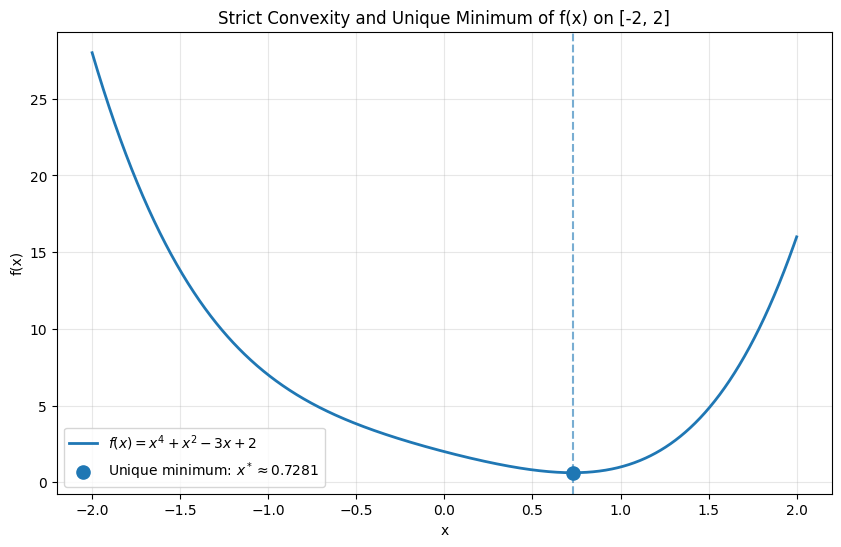

In [ ]:
# Find the stationary point by solving f'(x) = 0

stationary_point = sp.nsolve(f_prime, 0.5)

# Evaluate f at the stationary point
minimum_value = f_objective.subs(x, stationary_point).evalf()

print(f"Stationary point x* = {float(stationary_point):.10f}")
print(f"f(x*)               = {float(minimum_value):.10f}")

# Convert symbolic function to a numerical function
f_numeric = sp.lambdify(x, f_objective, "numpy")

# Generate function values
x_plot = np.linspace(-2, 2, 1000)
y_plot = f_numeric(x_plot)

x_min = float(stationary_point)
y_min = float(minimum_value)

# Plot the objective function
plt.figure(figsize=(10, 6))

plt.plot(
    x_plot,
    y_plot,
    linewidth=2,
    label=r"$f(x)=x^4+x^2-3x+2$"
)

# Plot the unique minimizer
plt.scatter(
    x_min,
    y_min,
    s=90,
    zorder=5,
    label=fr"Unique minimum: $x^*\approx{x_min:.4f}$"
)

# Vertical reference line at minimizer
plt.axvline(
    x=x_min,
    linestyle="--",
    alpha=0.6
)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Strict Convexity and Unique Minimum of f(x) on [-2, 2]")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

## 1(b) Implementation from scratch

The function below follows Algorithm 1 directly. It reuses one interior point and one stored function value after every interval reduction, so only one new function evaluation is needed per iteration. The final evaluation at the reported midpoint is used only to return the requested function value and is reported separately from the search-evaluation count.

In [ ]:
def golden_section_search(func, a, b, tolerance):
    """Minimize a unimodal scalar function on [a, b] from scratch."""
    if not (a < b):
        raise ValueError("The initial interval must satisfy a < b.")
    if tolerance <= 0:
        raise ValueError("The tolerance must be positive.")

    tau = (np.sqrt(5.0) - 1.0) / 2.0
    x1 = b - tau * (b - a)
    x2 = a + tau * (b - a)
    f1 = func(x1)
    f2 = func(x2)
    function_evaluations = 2
    intervals = [(a, b)]

    while b - a >= tolerance:
        if f1 > f2:
            a = x1
            x1, f1 = x2, f2
            x2 = a + tau * (b - a)
            f2 = func(x2)
        else:
            b = x2
            x2, f2 = x1, f1
            x1 = b - tau * (b - a)
            f1 = func(x1)
        function_evaluations += 1
        intervals.append((a, b))

    minimizer = (a + b) / 2.0
    minimum_value = func(minimizer)
    return {
        "minimizer": minimizer,
        "minimum_value": minimum_value,
        "final_interval": (a, b),
        "search_function_evaluations": function_evaluations,
        "intervals": intervals,
    }


def f(x):
    return x**4 + x**2 - 3*x + 2

## 1(c) Numerical result and interval figure

In [ ]:
result_q1 = golden_section_search(f, -2.0, 2.0, 1e-5)
left, right = result_q1["final_interval"]

print(f"Estimated minimizer: {result_q1['minimizer']:.12f}")
print(f"Function value:      {result_q1['minimum_value']:.12f}")
print(f"Final interval:      [{left:.12f}, {right:.12f}]")
print(f"Final width:         {right-left:.12e}")
print(f"Search evaluations:  {result_q1['search_function_evaluations']}")
print(f"Interval reductions: {len(result_q1['intervals'])-1}")

Estimated minimizer: 0.728080355966
Function value:      0.626867012076
Final interval:      [0.728075802273, 0.728084909658]
Final width:         9.107385178564e-06
Search evaluations:  29
Interval reductions: 27


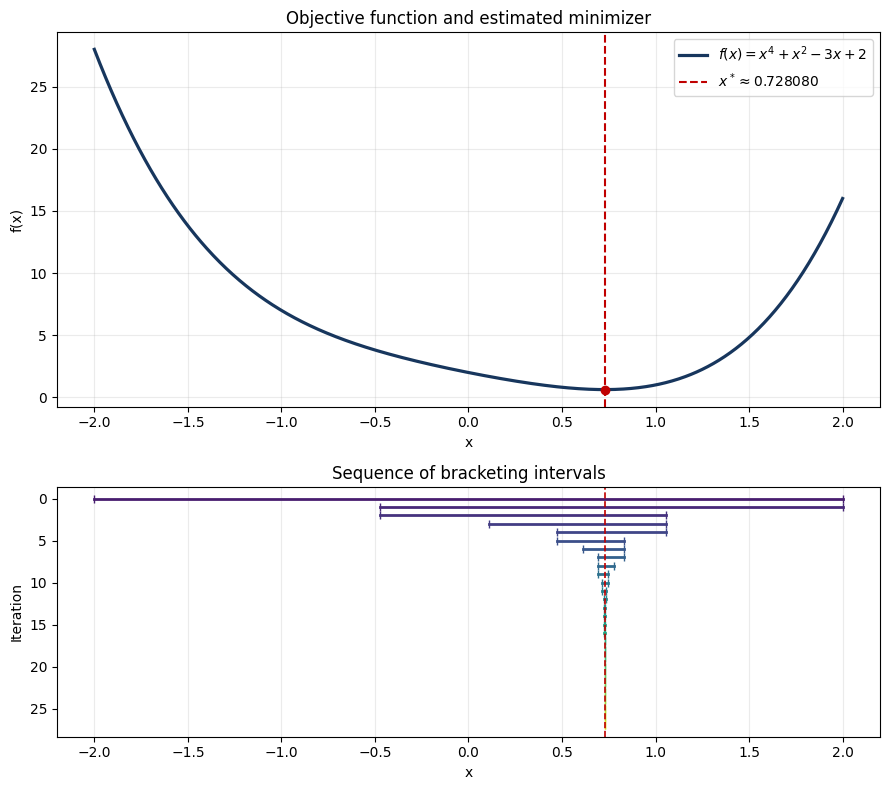

In [ ]:
x_grid = np.linspace(-2, 2, 800)
intervals = result_q1["intervals"]
x_star = result_q1["minimizer"]

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(9, 8), gridspec_kw={"height_ratios": [2.1, 1.4]}
)

ax1.plot(x_grid, f(x_grid), color="#17365D", linewidth=2.3,
         label=r"$f(x)=x^4+x^2-3x+2$")
ax1.axvline(x_star, color="#C00000", linestyle="--", linewidth=1.5,
            label=rf"$x^*\approx{x_star:.6f}$")
ax1.scatter([x_star], [f(x_star)], color="#C00000", zorder=3)
ax1.set(xlabel="x", ylabel="f(x)", title="Objective function and estimated minimizer")
ax1.grid(alpha=0.25)
ax1.legend()

colors = plt.cm.viridis(np.linspace(0.08, 0.95, len(intervals)))
for iteration, ((left, right), color) in enumerate(zip(intervals, colors)):
    ax2.plot([left, right], [iteration, iteration], color=color, linewidth=2)
    ax2.plot([left, right], [iteration, iteration], "|", color=color, markersize=6)

ax2.axvline(x_star, color="#C00000", linestyle="--", linewidth=1.2)
ax2.invert_yaxis()
ax2.set(xlabel="x", ylabel="Iteration", title="Sequence of bracketing intervals")
ax2.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

The minimizer remains inside every bracket. The returned midpoint is within half the final bracket width of the unique minimizer, giving an absolute error bound below $5\times10^{-6}$.  
The interval plot shows geometric contraction toward approximately $x=0.72808$.
The 29 reported evaluations are those performed by the search itself: two initial evaluations plus one for each of 27 reductions.   
Evaluating the final midpoint to report $f(x^*)$ adds one post-search evaluation.

### Numerical Summary
| Quantity | Result |
|---|---:|
| Estimated minimizer | 0.7280803560 |
| Function value | 0.6268670121 |
| Final interval | [0.7280758023, 0.7280849097] |
| Function evaluations including returned midpoint | 30 |
| Interval reductions | 27 |  

The independent derivative-root check gives 0.7280821231. The returned estimate differs by approximately $1.77\times10^{-6}$, below the guaranteed midpoint bound.

# Question 2 Locating a Pawi Nest


## 2(a) Nonlinear least squares formulation

For sensor $i$, define

$$d_i(x_N,y_N)=\sqrt{(x_i-x_N)^2+(y_i-y_N)^2}$$

and

$$\widehat I_i=A\exp[-\lambda d_i(x_N,y_N)].$$

With observed intensity $I_i$, estimate the four parameters by minimizing

$$
\min_{x_N,y_N,A,\lambda}\;F(x_N,y_N,A,\lambda)
=\frac12\sum_{i=1}^{25}\left[Ae^{-\lambda d_i(x_N,y_N)}-I_i\right]^2,
\qquad A>0,\;\lambda>0.
$$

The factor $1/2$ does not change the minimizer and simplifies the gradient. In keeping with the question, no box constraints are imposed on $x_N$ or $y_N$.

## 2(b) Positive re-parameterization

Set $A=e^\alpha$ and $\lambda=e^\beta$, with $\alpha,\beta\in\mathbb R$. For every finite real value, the exponential is strictly positive, and every strictly positive $A,\lambda$ has a real logarithm. The reparameterization therefore covers exactly the allowed positive parameters and yields an unconstrained problem in $\theta=(x_N,y_N,\alpha,\beta)$.  
  

**Alternatively**,  
Let

$$A=e^\alpha,\qquad \lambda=e^\beta,$$

where $\alpha,\beta\in\mathbb R$. The exponential is strictly positive for every finite real argument, so this transformation guarantees $A>0$ and $\lambda>0$ while leaving $(x_N,y_N,\alpha,\beta)$ unconstrained.

The optimization vector is $\theta=(x_N,y_N,\alpha,\beta)$. For prediction $p_i=e^\alpha e^{-e^\beta d_i}$, residual $r_i=p_i-I_i$, and $\lambda=e^\beta$, the prediction derivatives are

$$
\frac{\partial p_i}{\partial x_N}=\lambda p_i\frac{x_i-x_N}{d_i},\quad
\frac{\partial p_i}{\partial y_N}=\lambda p_i\frac{y_i-y_N}{d_i},\quad
\frac{\partial p_i}{\partial\alpha}=p_i,\quad
\frac{\partial p_i}{\partial\beta}=-\lambda d_i p_i.
$$

Thus $\nabla F=J^Tr$. At the exceptional case $d_i=0$, the code replaces the denominator only by a very small positive value to avoid division by zero; the corresponding numerator is also zero.

## 2(c) BFGS implementation and multi-start estimation

The following BFGS method is implemented from scratch. It uses the analytic gradient above, an Armijo backtracking line search, the inverse-Hessian BFGS update, and a steepest-descent reset if the computed direction is not a descent direction. No nonlinear least-squares solver or general-purpose optimizer is called.

In [ ]:
sensor_x = np.tile(np.array([0., 2., 4., 6., 8.]), 5)
sensor_y = np.repeat(np.array([0., 2., 4., 6., 8.]), 5)
observed = np.array([
    [12.9, 21.8, 24.5, 17.2, 19.6],
    [26.0, 32.0, 39.7, 34.1, 27.9],
    [26.8, 44.2, 64.1, 61.7, 33.6],
    [28.5, 44.6, 76.5, 62.7, 36.9],
    [24.4, 32.3, 44.1, 42.0, 30.8],
]).ravel()


def pawi_objective_and_gradient(theta):
    x_n, y_n, alpha, beta = theta
    # Clipping is only a numerical safeguard during rejected trial steps.
    A = np.exp(np.clip(alpha, -50.0, 50.0))
    lam = np.exp(np.clip(beta, -50.0, 50.0))

    dx = sensor_x - x_n
    dy = sensor_y - y_n
    distance = np.hypot(dx, dy)
    safe_distance = np.maximum(distance, 1e-12)
    prediction = A * np.exp(-lam * distance)
    residual = prediction - observed
    objective = 0.5 * residual @ residual

    jacobian = np.column_stack([
        lam * prediction * dx / safe_distance,
        lam * prediction * dy / safe_distance,
        prediction,
        -lam * distance * prediction,
    ])
    gradient = jacobian.T @ residual
    return objective, gradient


def bfgs_from_scratch(theta0, gradient_tolerance=1e-6,
                      function_tolerance=1e-12, max_iterations=500):
    theta = np.asarray(theta0, dtype=float).copy()
    inverse_hessian = np.eye(theta.size)
    objective, gradient = pawi_objective_and_gradient(theta)
    evaluations = 1

    for iteration in range(max_iterations):
        if np.linalg.norm(gradient, ord=np.inf) <= gradient_tolerance:
            return theta, objective, iteration, evaluations, "gradient tolerance"

        direction = -inverse_hessian @ gradient
        if gradient @ direction >= 0:  # safeguard: force a descent direction
            inverse_hessian = np.eye(theta.size)
            direction = -gradient

        directional_derivative = gradient @ direction
        step = 1.0
        for _ in range(60):
            candidate = theta + step * direction
            new_objective, new_gradient = pawi_objective_and_gradient(candidate)
            evaluations += 1
            if (np.isfinite(new_objective) and
                    new_objective <= objective + 1e-4 * step * directional_derivative):
                break
            step *= 0.5
        else:
            return theta, objective, iteration, evaluations, "line search failed"

        s = candidate - theta
        y = new_gradient - gradient
        curvature = y @ s
        if curvature > 1e-12:
            rho = 1.0 / curvature
            identity = np.eye(theta.size)
            inverse_hessian = (
                (identity - rho * np.outer(s, y))
                @ inverse_hessian
                @ (identity - rho * np.outer(y, s))
                + rho * np.outer(s, s)
            )
        else:
            inverse_hessian = np.eye(theta.size)

        old_objective = objective
        theta, objective, gradient = candidate, new_objective, new_gradient
        small_objective_change = abs(old_objective - objective) <= (
            function_tolerance * (1.0 + abs(objective))
        )
        small_step = np.linalg.norm(s, ord=np.inf) <= (
            1e-7 * (1.0 + np.linalg.norm(theta, ord=np.inf))
        )
        if small_objective_change and small_step:
            return theta, objective, iteration + 1, evaluations, "step/objective tolerance"

    return theta, objective, max_iterations, evaluations, 'maximum iterations'

In [ ]:
initial_points = [
    (4.0, 4.0, 80.0, 0.20),
    (2.0, 6.0, 100.0, 0.50),
    (7.0, 2.0, 60.0, 0.10),
]

rows = []
solutions = []
for run, (x0, y0, A0, lambda0) in enumerate(initial_points, start=1):
    theta0 = np.array([x0, y0, np.log(A0), np.log(lambda0)])
    theta, objective, iterations, evaluations, reason = bfgs_from_scratch(theta0)
    x_n, y_n, alpha, beta = theta
    solutions.append((theta, objective))
    rows.append({
        "Start": f"Start {run}", "x_N start": x0, "y_N start": y0,
        "A start": A0, "lambda start": lambda0,
        "x_N estimate": x_n, "y_N estimate": y_n,
        "A estimate": np.exp(alpha), "lambda estimate": np.exp(beta),
        "Objective": objective, "Iterations": iterations, "Stop reason": reason,
    })

results_q2 = pd.DataFrame(rows)
print(results_q2.to_string(index=False))

theta_hat, objective_hat = solutions[0]
x_hat, y_hat, alpha_hat, beta_hat = theta_hat
print("\nFinal parameter estimates (using Start 1):")
print(f"x_N    = {x_hat:.6f}")
print(f"y_N    = {y_hat:.6f}")
print(f"A      = {np.exp(alpha_hat):.6f}")
print(f"lambda = {np.exp(beta_hat):.6f}")
print(f"SSE    = {2*objective_hat:.6f}")
print(f"RMSE   = {np.sqrt(2*objective_hat/observed.size):.6f}")

  Start  x_N start  y_N start      A start  lambda start  x_N estimate  y_N estimate  A estimate  lambda estimate   Objective  Iterations              Stop reason
Start 1 4.00000000 4.00000000  80.00000000    0.20000000    4.59407396    5.26828546 96.34148891       0.26972374 58.45869439          16 step/objective tolerance
Start 2 2.00000000 6.00000000 100.00000000    0.50000000    4.59407396    5.26828546 96.34148891       0.26972374 58.45869439          17 step/objective tolerance
Start 3 7.00000000 2.00000000  60.00000000    0.10000000    4.59407396    5.26828546 96.34148890       0.26972374 58.45869439          17 step/objective tolerance

Final parameter estimates (using Start 1):
x_N    = 4.594074
y_N    = 5.268285
A      = 96.341489
lambda = 0.269724
SSE    = 116.917389
RMSE   = 2.162567


**Therefore:** All three materially different starting points converge to the same reported solution to the displayed precision. The estimated nest location is approximately $(4.594,5.268)$, the fitted intensity at the nest is $A\approx96.341$, and intensity decays at rate $\lambda\approx0.2697$ per distance unit. The multi-start agreement provides empirical evidence that the reported solution is stable for these starts, although it is not a formal proof that no other local minimum exists.

# Question 3 Expanding Pallet Town


## 3(a) Original formulation

Let $x_S,x_F,x_T,x_A\geq0$ denote acres assigned to Starter Cottages, Family Homes, Trainer Townhouses, and Apartments. Fractional acreage is allowed. Define

$$C(x)=120x_S+160x_F+190x_T+260x_A$$

and $U(x)=\max\{3000,C(x)\}$, with all *monetary quantities in thousands of dollars*. The original problem is

$$\max\;500x_S+640x_F+790x_T+1080x_A-U(x)$$

subject to

$$x_S+x_F+x_T+x_A\leq18,$$
$$22x_S+30x_F+45x_T+70x_A\leq750,$$
$$2x_S+2.8x_F+3.6x_T+5x_A\leq60,$$
$$x_S\geq0.40(x_S+x_F+x_T+x_A),$$
$$900x_S+1250x_F+1500x_T+2200x_A+U(x)\leq26000,$$
$$x_S,x_F,x_T,x_A\geq0.$$

The budget includes construction cost and the actual utility connection charge. The objective uses the stated expected net return before utility charge and therefore subtracts only the actual utility charge.

## 3(b) Linear reformulation

Introduce $u$ as the actual utility connection charge. The complete linear program is

$$\max\;500x_S+640x_F+790x_T+1080x_A-u$$

subject to the first four resource/share constraints above and

$$900x_S+1250x_F+1500x_T+2200x_A+u\leq26000,$$
$$u\geq3000,$$
$$u\geq120x_S+160x_F+190x_T+260x_A,$$
$$x_S,x_F,x_T,x_A,u\geq0.$$

The two lower bounds imply $u\geq\max\{3000,C(x)\}$. Because $u$ is subtracted in the maximization objective and consumes budget, any optimum selects its smallest feasible value. Thus $u=\max\{3000,C(x)\}$ at an optimum, making the reformulation equivalent to the original model.

## **Julia** and **JuMP** setup for Google Colab for questions 3(c) to 3(e)

The following cell installs Julia 1.10.10 in Colab and installs JuMP and the open-source HiGHS solver.  
It is idempotent: rerunning it reuses an existing Julia installation and package environment.

In [ ]:
%%bash
set -euo pipefail

JULIA_VERSION="1.10.10"
JULIA_HOME="/content/julia-${JULIA_VERSION}"
JULIA_ARCHIVE="/tmp/julia-${JULIA_VERSION}.tar.gz"
JULIA_URL="https://julialang-s3.julialang.org/bin/linux/x64/1.10/julia-${JULIA_VERSION}-linux-x86_64.tar.gz"

if [ ! -x "${JULIA_HOME}/bin/julia" ]; then
  mkdir -p "${JULIA_HOME}"
  curl -fsSL "${JULIA_URL}" -o "${JULIA_ARCHIVE}"
  tar --no-same-owner -xzf "${JULIA_ARCHIVE}" -C "${JULIA_HOME}" --strip-components=1
fi

"${JULIA_HOME}/bin/julia" --version
"${JULIA_HOME}/bin/julia" --startup-file=no -e '
  using Pkg
  Pkg.add([Pkg.PackageSpec(name="JuMP", version="1"),
           Pkg.PackageSpec(name="HiGHS", version="1")])
  Pkg.precompile()
'

julia version 1.10.10


   Resolving package versions...
  No Changes to `~/.julia/environments/v1.10/Project.toml`
  No Changes to `~/.julia/environments/v1.10/Manifest.toml`


## 3(c)–3(e) JuMP model, shadow prices, and budget sensitivity

`shadow_price` is used instead of the raw solver dual so that the reported sign directly represents the change in the maximized objective per one-unit increase in the constraint right-hand side. Here, one monetary unit is $1,000.

In [ ]:
%%bash
set -euo pipefail

/content/julia-1.10.10/bin/julia --startup-file=no - <<'JULIA'
using JuMP, HiGHS, Printf

function solve_pallet(budget_rhs)
    model = Model(HiGHS.Optimizer)
    set_silent(model)

    @variable(model, xS >= 0)
    @variable(model, xF >= 0)
    @variable(model, xT >= 0)
    @variable(model, xA >= 0)
    @variable(model, u >= 0)

    land = @constraint(model, xS + xF + xT + xA <= 18)
    electricity = @constraint(model, 22xS + 30xF + 45xT + 70xA <= 750)
    water = @constraint(model, 2.0xS + 2.8xF + 3.6xT + 5.0xA <= 60)
    starter_share = @constraint(model,
        xS >= 0.40 * (xS + xF + xT + xA))
    budget_limit = @constraint(model,
        900xS + 1250xF + 1500xT + 2200xA + u <= budget_rhs)
    utility_floor = @constraint(model, u >= 3000)
    utility_assessment = @constraint(model,
        u >= 120xS + 160xF + 190xT + 260xA)

    @objective(model, Max,
        500xS + 640xF + 790xT + 1080xA - u)
    optimize!(model)

    vars = (; xS, xF, xT, xA, u)
    cons = (; land, electricity, water, starter_share, budget_limit,
             utility_floor, utility_assessment)
    return model, vars, cons
end

# Base model: budget = $26 million = 26,000 thousand dollars.
model, vars, cons = solve_pallet(26_000.0)
@assert termination_status(model) == MOI.OPTIMAL

@printf("Status: %s\n", string(termination_status(model)))
@printf("xS = %.6f, xF = %.6f, xT = %.6f, xA = %.6f acres\n",
        value(vars.xS), value(vars.xF), value(vars.xT), value(vars.xA))
@printf("u = %.6f thousand dollars\n", value(vars.u))
@printf("Maximum net return = %.6f thousand dollars\n", objective_value(model))

println("\nResource slacks and shadow prices")
for (name, con) in [
    ("Land", cons.land),
    ("Electricity", cons.electricity),
    ("Water", cons.water),
    ("Budget", cons.budget_limit),
]
    slack = normalized_rhs(con) - value(constraint_object(con).func)
    @printf("%-12s slack = %10.6f, shadow price = %10.6f\n",
            name, slack, shadow_price(con))
end

# for 3d and 3e - Sensitivity test: raise the budget by $500,000 = 500 thousand dollars.
base_objective = objective_value(model)
budget_shadow_price = shadow_price(cons.budget_limit)
predicted_increase = 500.0 * budget_shadow_price

model2, vars2, cons2 = solve_pallet(26_500.0)
@assert termination_status(model2) == MOI.OPTIMAL
actual_increase = objective_value(model2) - base_objective

println("\nBudget sensitivity")
@printf("Predicted objective increase = %.6f thousand dollars\n", predicted_increase)
@printf("Actual objective increase    = %.6f thousand dollars\n", actual_increase)
@printf("New maximum net return       = %.6f thousand dollars\n", objective_value(model2))
@printf("New allocation: xS = %.6f, xF = %.6f, xT = %.6f, xA = %.6f acres\n",
        value(vars2.xS), value(vars2.xF), value(vars2.xT), value(vars2.xA))
JULIA


Status: OPTIMAL
xS = 7.200000, xF = 0.000000, xT = 10.342857, xA = 0.457143 acres
u = 3000.000000 thousand dollars
Maximum net return = 9264.571429 thousand dollars

Resource slacks and shadow prices
Land         slack =   0.000000, shadow price = 152.000000
Electricity  slack =  94.171429, shadow price =   0.000000
Water        slack =   6.080000, shadow price =   0.000000
Budget       slack =   0.000000, shadow price =   0.414286

Budget sensitivity
Predicted objective increase = 207.142857 thousand dollars
Actual objective increase    = 207.142857 thousand dollars
New maximum net return       = 9471.714286 thousand dollars
New allocation: xS = 7.200000, xF = 0.000000, xT = 9.628571, xA = 1.171429 acres


##3 (c) - JuMP implementation and solution

| Development type | Acres |
|---|---|
| Starter Cottage | 7.2000 |
| Family Home | 0.0000 |
| Trainer Townhouse | 10.3429 |
| Apartment | 0.4571 |
| **Total** | **18.0000** |

* **Maximum expected net return:** about **\$9.265 million** (9,264.571 in \\$000). This is \\$12.265 million of net return before the utility charge, less the \$3 million charge.
* **Binding constraints:** **land** (all 18 acres used) and **budget** (\\$23.0m construction + \\$3.0m utility charge = \$26.0m).
* **Not binding:** **electricity** (about 655.8 kW used, 94.2 kW spare) and **water** (53.92 thousand gal/day used, about 6,080 gal/day spare).
* Two further constraints are also binding: the **40% Starter Cottage requirement** ($7.2 = 0.4 \times 18$) and the **\$3m minimum utility charge**. The assessments sum to $C(x^*) = 2948 < 3000$, so the Council pays the minimum charge.

**Planning recommendation-** Develop all 18 acres: the minimum permitted 7.2 acres of Starter Cottages, about 10.34 acres of Trainer Townhouses, and a small Apartment component of about 0.46 acres. No Family Homes are allocated; in this model they are dominated by the alternatives. Land and money are the effective limits on the plan; the expanded electricity and water networks have headroom at this scale, so further utility investment would not improve the return. The Starter Cottage policy is costly in the sense that it binds, and it holds Starter acreage at its floor. The fractional values are acceptable for an acreage allocation; when individual homes are laid out later they will need rounding, which may change the return slightly.


## 3(d) Shadow-price interpretation

| Constraint | Shadow price | Meaning |
|---|---|---|
| Land | 152.0 (\$000/acre) | One more acre of developable land would raise the optimal net return by about **\$152,000**, holding everything else fixed. |
| Electricity | 0 | Extra peak capacity is worth nothing at the margin. |
| Water | 0 | Extra water capacity is worth nothing at the margin. |
| Budget | 0.4143 | Each extra \$1 of budget raises optimal net return by about **\$0.41**; each extra \$1,000 adds about \$414.|

**Why the budget shadow price is 0.4143:** With land and the Starter floor binding, the cheapest way to use an extra dollar is to convert Townhouse acres into Apartment acres. Each converted acre costs $2200 - 1500 = 700$ more to build and returns $1080 - 790 = 290$ more. Because $C(x) < 3000$, the higher assessment does not raise the charge actually paid.  
So the marginal rate is $290/700 \approx 0.4143$.  

**Zero shadow prices:** Electricity and water both have unused capacity at the optimum. By complementary slackness, a constraint with positive slack must have a zero dual value: relaxing it by a small amount does not change which plans are feasible near the optimum, so it cannot change the optimal return. Equivalently, tightening it slightly also costs nothing, up to the amount of spare capacity (about 94.2 kW and 6.08 thousand gal/day). A zero shadow price does **not** mean the resource is unimportant; it means it is not the limiting resource at this solution. If capacity were cut by more than the current slack, the constraint would become binding and its shadow price would generally become positive.

**Supplementary:** The minimum-charge constraint has a shadow price of about $-1.414$: raising the floor by \$1 costs \$1 directly plus \$1 of budget that would otherwise earn \$0.414. The starter-share constraint is also binding with a negative shadow price; loosening the 40% policy would increase the return.


## 3(e) Increasing the budget by \$500,000

The budget is in \$000, so the increase is $\Delta b = 500$.

* **Predicted increase:** $0.4143 \times 500 \approx 207.143$ (\$000), i.e. about **\$207,143**.
* **Actual increase after re-solving:** 9,471.714 − 9,264.571 = 207.143 (\$000). The prediction is **exact** up to solver tolerance.
* The new plan keeps 7.2 acres of Starter Cottages and the full 18 acres, and shifts about 0.714 acres from Trainer Townhouses to Apartments (Townhouses ≈ 9.629, Apartments ≈ 1.171). $C(x)$ rises from 2948 to 2998, still below 3000, so the utility charge stays at \$3m.

**Why the match is exact:** An LP's optimal value is piecewise linear in a right-hand side. Within the range where the optimal basis does not change, the shadow price is the exact slope, not just a first-order approximation. The sensitivity report shows the allowable increase is about 520 (\$000): beyond roughly \$520,000 of extra budget, $C(x)$ reaches 3000 and the assessment constraint $u \ge C(x)$ becomes binding. From that point each Townhouse-to-Apartment acre also raises the utility charge by $260 - 190 = 70$, so the marginal value of budget falls to $(290 - 70)/(700 + 70) = 220/770 \approx 0.2857$. The sweep table shows the shadow-price prediction overstating the gain for increases beyond 520 (for example, an increase of \$1m would yield about \$352,600, not \$414,300).

**Recommendation to the Council:** The **\$500,000** from the Kanto Development Bank would add about **\$207,000** of expected net return, a return of roughly 41 cents per dollar. Whether that is worthwhile depends on the financing cost of the extra funds, which is outside this model. Additional funding beyond about **\$520,000** would still help, but at a lower marginal rate because the utility charge would then start to rise above the \$3m minimum.